In [20]:
print("My E-Commerce Data Analysis Project")
print("Hello, Saranya!")

My E-Commerce Data Analysis Project
Hello, Saranya!


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [22]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\usara\Downloads\archive\Sample - Superstore.csv"
)

print("Dataset loaded successfully!")

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xa0 in position 2944: invalid start byte

In [23]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\usara\Downloads\archive\Sample - Superstore.csv",
    encoding="cp1252"
)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [24]:
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [25]:
df.shape


(9994, 21)

In [26]:
df.columns.tolist()


['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [27]:
df.isnull().sum()


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [30]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [31]:
print("First order date:", df["Order Date"].min())
print("Last order date:", df["Order Date"].max())

First order date: 2014-01-03 00:00:00
Last order date: 2017-12-30 00:00:00


In [32]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df[["Order Date", "Ship Date", "Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2016-11-08,2016-11-11,3
1,2016-11-08,2016-11-11,3
2,2016-06-12,2016-06-16,4
3,2015-10-11,2015-10-18,7
4,2015-10-11,2015-10-18,7


In [33]:
print("Negative shipping durations:", (df["Shipping Days"] < 0).sum())

print("Minimum shipping days:", df["Shipping Days"].min())
print("Maximum shipping days:", df["Shipping Days"].max())

Negative shipping durations: 0
Minimum shipping days: 0
Maximum shipping days: 7


In [34]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity Sold: 37873
Profit Margin: 12.47 %


In [35]:

# Group the data by product category
category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

# Calculate profit margin for each category
category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
) * 100

# Sort categories by sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales", ascending=False
)

# Display the results
category_analysis.round(2)


,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
Category,,,,
Technology,836154.03,145454.95,6939,17.40
Furniture,741999.80,18451.27,8028,2.49
Office Supplies,719047.03,122490.80,22906,17.04


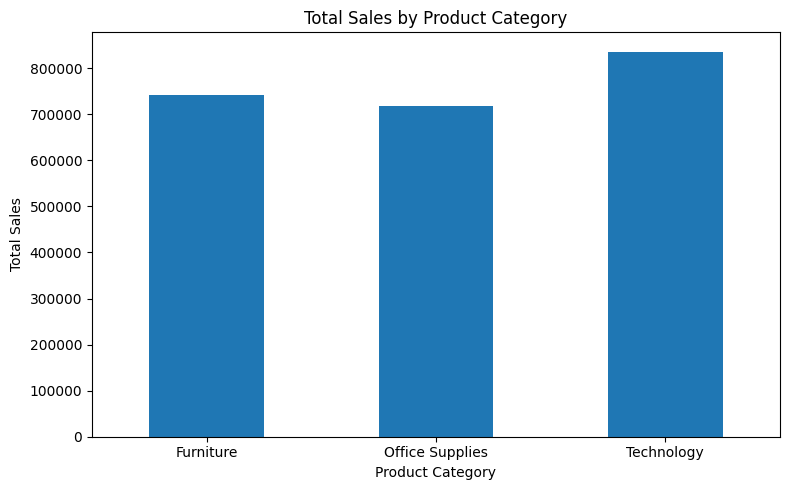

In [36]:

import matplotlib.pyplot as plt

# Get total sales for each category
sales_by_category = df.groupby("Category")["Sales"].sum()

# Create the bar chart
sales_by_category.plot(kind="bar", figsize=(8, 5))

# Add labels and title
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

# Display the chart
plt.tight_layout()
plt.show()


In [37]:

discount_analysis = df.groupby("Category").agg(
    Average_Discount=("Discount", "mean"),
    Total_Profit=("Profit", "sum"),
    Total_Sales=("Sales", "sum")
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"]
) * 100

discount_analysis.round(3)


,Average_Discount,Total_Profit,Total_Sales,Profit_Margin
Category,,,,
Furniture,0.174,18451.273,741999.795,2.487
Office Supplies,0.157,122490.801,719047.032,17.035
Technology,0.132,145454.948,836154.033,17.396


In [38]:

# Calculate the correlation between discount and profit
correlation = df["Discount"].corr(df["Profit"])

print("Correlation between Discount and Profit:", round(correlation, 3))

# Compare profit at different discount levels
discount_analysis = df.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Profit", "count")
)

discount_analysis.round(2)


Correlation between Discount and Profit: -0.219


,Average_Profit,Total_Profit,Number_of_Orders
Discount,,,
0.00,66.90,320987.60,4798
0.10,96.06,9029.18,94
0.15,27.29,1418.99,52
0.20,24.70,90337.31,3657
0.30,-45.68,-10369.28,227
0.32,-88.56,-2391.14,27
0.40,-111.93,-23057.05,206
0.45,-226.65,-2493.11,11
0.50,-310.70,-20506.43,66


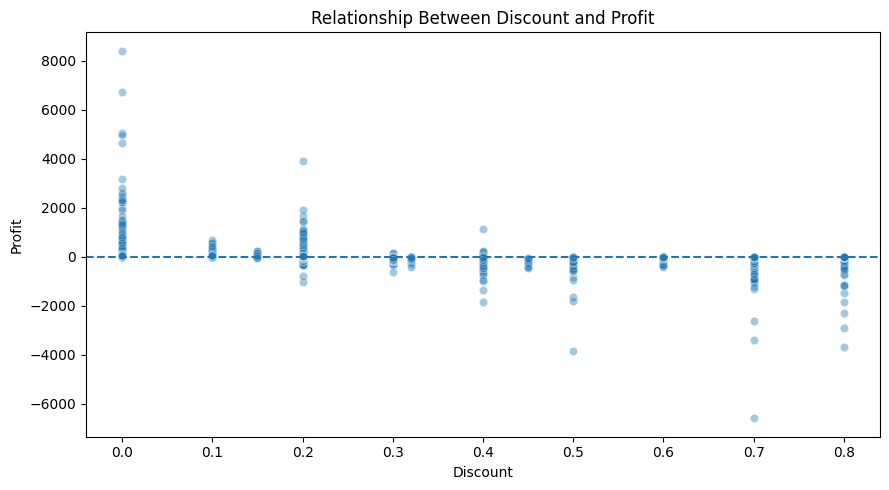

In [39]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.4
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()


In [40]:

# Group sales records by product
product_analysis = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

# Keep products with negative total profit
loss_products = product_analysis[
    product_analysis["Total_Profit"] < 0
]

# Show the 10 products with the largest total losses
loss_products = loss_products.sort_values(
    by="Total_Profit",
    ascending=True
)

loss_products.head(10).round(2)


,Total_Sales,Total_Profit,Units_Sold
Product Name,,,
Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,9
Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,18
Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99,4
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.64,-2876.12,27
Bush Advantage Collection Racetrack Conference Table,9544.72,-1934.40,33
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
Martin Yale Chadless Opener Electric Letter Opener,16656.20,-1299.18,22
Balt Solid Wood Round Tables,6518.75,-1201.06,19


In [41]:

# Calculate product-level discount statistics
product_discounts = df.groupby("Product Name").agg(
    Average_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Records=("Profit", "count")
)

# Select the 10 products with the largest total losses
top_loss_products = product_discounts.sort_values(
    by="Total_Profit",
    ascending=True
).head(10)

top_loss_products.round(3)


,Average_Discount,Total_Sales,Total_Profit,Number_of_Records
Product Name,,,,
Cubify CubeX 3D Printer Double Head Print,0.533,11099.963,-8879.970,3
Lexmark MX611dhe Monochrome Laser Printer,0.400,16829.901,-4589.973,4
Cubify CubeX 3D Printer Triple Head Print,0.500,7999.980,-3839.990,1
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,0.280,9917.640,-2876.116,5
Bush Advantage Collection Racetrack Conference Table,0.350,9544.725,-1934.398,7
GBC DocuBind P400 Electric Binding System,0.450,17965.068,-1878.166,6
Cisco TelePresence System EX90 Videoconferencing Unit,0.500,22638.480,-1811.078,1
Martin Yale Chadless Opener Electric Letter Opener,0.100,16656.200,-1299.184,6
Balt Solid Wood Round Tables,0.200,6518.754,-1201.058,4


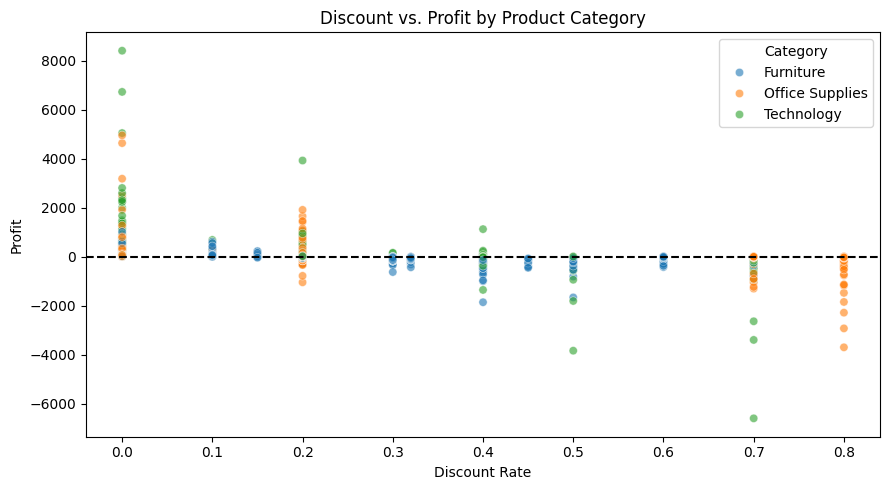

In [42]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Discount vs. Profit by Product Category")
plt.xlabel("Discount Rate")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()


In [43]:

# Create a monthly sales summary
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

# Convert the monthly period index to timestamps
monthly_sales.index = monthly_sales.index.to_timestamp()

# Display the first 12 months
monthly_sales.head(12)


Order Date
2014-01-01    14236.8950
2014-02-01     4519.8920
2014-03-01    55691.0090
2014-04-01    28295.3450
2014-05-01    23648.2870
2014-06-01    34595.1276
2014-07-01    33946.3930
2014-08-01    27909.4685
2014-09-01    81777.3508
2014-10-01    31453.3930
2014-11-01    78628.7167
2014-12-01    69545.6205
Freq: MS, Name: Sales, dtype: float64

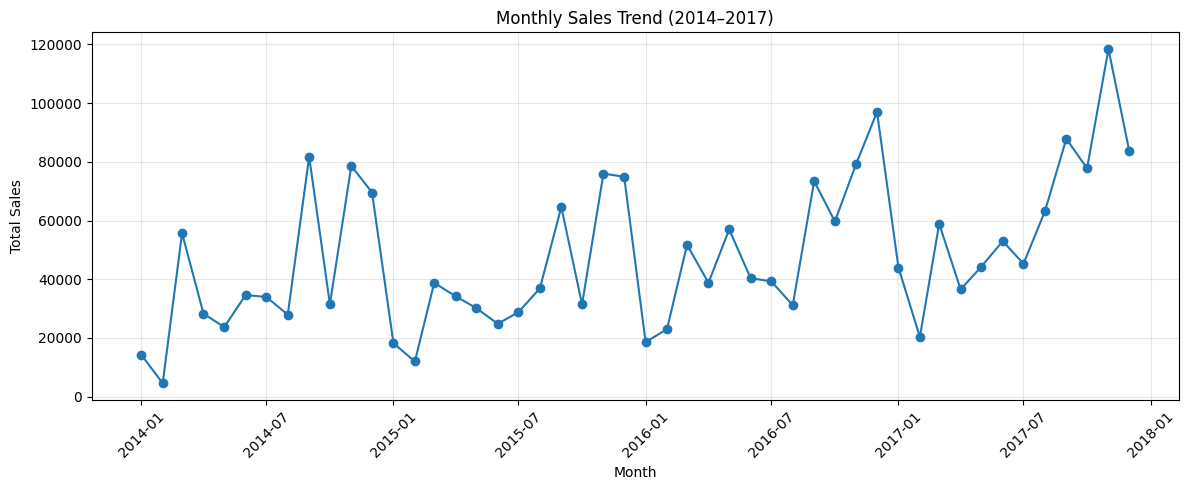

In [44]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [45]:

print("Highest sales month:")
print(monthly_sales.idxmax(), round(monthly_sales.max(), 2))

print("\nLowest sales month:")
print(monthly_sales.idxmin(), round(monthly_sales.min(), 2))


Highest sales month:
2017-11-01 00:00:00 118447.82

Lowest sales month:
2014-02-01 00:00:00 4519.89


In [46]:

# Extract the year from each order date
df["Year"] = df["Order Date"].dt.year

# Calculate yearly business performance
yearly_analysis = df.groupby("Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

# Calculate profit margin for each year
yearly_analysis["Profit_Margin"] = (
    yearly_analysis["Total_Profit"]
    / yearly_analysis["Total_Sales"]
) * 100

yearly_analysis.round(2)


,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
Year,,,,
2014,484247.50,49543.97,7581,10.23
2015,470532.51,61618.60,7979,13.10
2016,609205.60,81795.17,9837,13.43
2017,733215.26,93439.27,12476,12.74


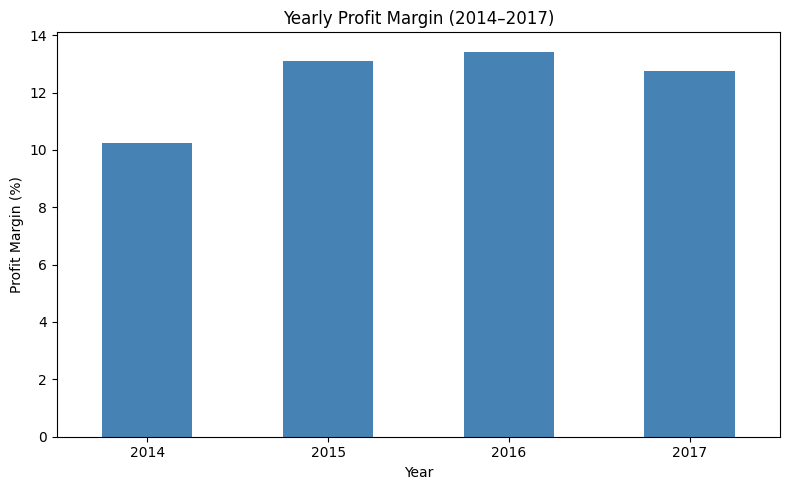

In [47]:

plt.figure(figsize=(8, 5))

yearly_analysis["Profit_Margin"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("Yearly Profit Margin (2014–2017)")
plt.xlabel("Year")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [48]:

yearly_growth = yearly_analysis[
    ["Total_Sales", "Total_Profit"]
].pct_change() * 100

yearly_growth.round(2)


,Total_Sales,Total_Profit
Year,,
2014,NaN,NaN
2015,-2.83,24.37
2016,29.47,32.74
2017,20.36,14.24


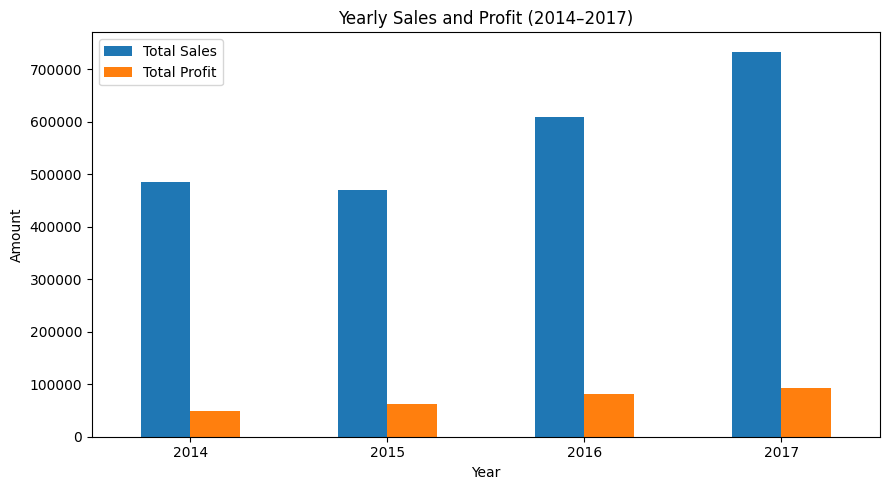

In [49]:
yearly_analysis[["Total_Sales", "Total_Profit"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Yearly Sales and Profit (2014–2017)")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.legend(["Total Sales", "Total Profit"])
plt.tight_layout()
plt.show()

In [50]:
subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

subcategory_analysis.round(2)

,Total_Sales,Total_Profit,Units_Sold
Sub-Category,,,
Copiers,149528.03,55617.82,234
Phones,330007.05,44515.73,3289
Accessories,167380.32,41936.64,2976
Paper,78479.21,34053.57,5178
Binders,203412.73,30221.76,5974
Chairs,328449.10,26590.17,2356
Storage,223843.61,21278.83,3158
Appliances,107532.16,18138.01,1729
Furnishings,91705.16,13059.14,3563


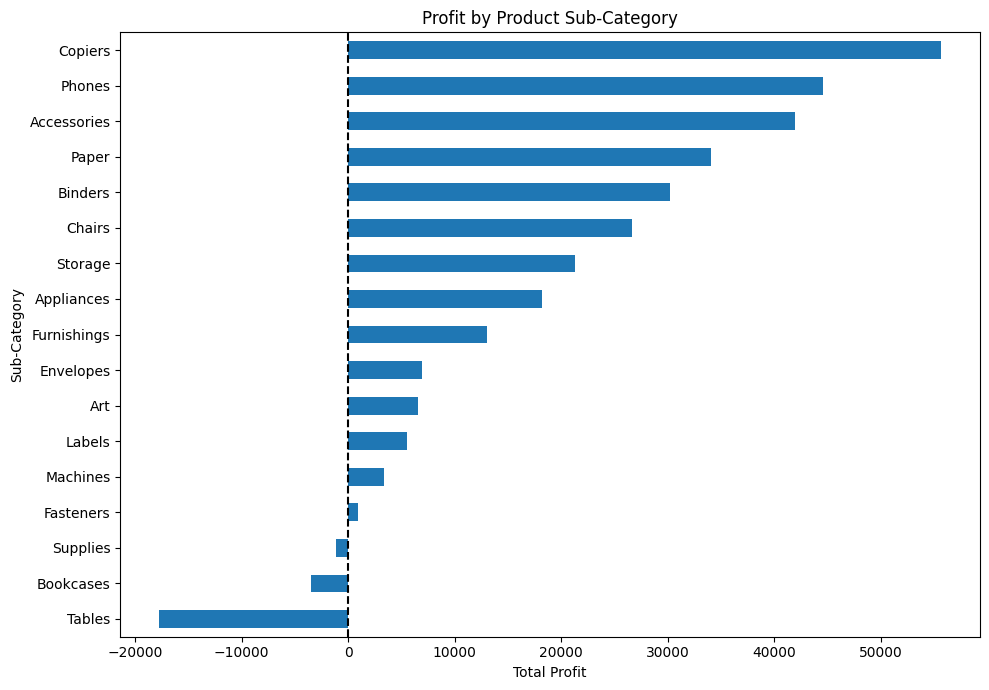

In [51]:
plt.figure(figsize=(10, 7))

subcategory_analysis["Total_Profit"].sort_values().plot(
    kind="barh"
)

plt.axvline(x=0, color="black", linestyle="--")
plt.title("Profit by Product Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [52]:
subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
) * 100

subcategory_analysis.sort_values(
    by="Profit_Margin",
    ascending=False
).round(2)

,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
Sub-Category,,,,
Labels,12486.31,5546.25,1400,44.42
Paper,78479.21,34053.57,5178,43.39
Envelopes,16476.40,6964.18,906,42.27
Copiers,149528.03,55617.82,234,37.20
Fasteners,3024.28,949.52,914,31.40
Accessories,167380.32,41936.64,2976,25.05
Art,27118.79,6527.79,3000,24.07
Appliances,107532.16,18138.01,1729,16.87
Binders,203412.73,30221.76,5974,14.86


In [53]:
loss_category_analysis = df[
    df["Sub-Category"].isin(
        ["Tables", "Bookcases", "Supplies"]
    )
].groupby("Sub-Category").agg(
    Average_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Number_of_Orders=("Order ID", "nunique")
)

loss_category_analysis.round(2)

,Average_Discount,Total_Sales,Total_Profit,Number_of_Orders
Sub-Category,,,,
Bookcases,0.21,114880.00,-3472.56,224
Supplies,0.08,46673.54,-1189.10,187
Tables,0.26,206965.53,-17725.48,307


In [54]:
tables_analysis = df[
    df["Sub-Category"] == "Tables"
].groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Records=("Profit", "count"),
    Total_Sales=("Sales", "sum")
)

tables_analysis.round(2)

,Average_Profit,Total_Profit,Number_of_Records,Total_Sales
Discount,,,,
0.00,184.39,13276.30,72,71578.76
0.20,-4.28,-303.56,71,45430.23
0.30,-63.01,-3402.33,54,25182.15
0.40,-215.83,-16187.40,75,45614.41
0.45,-226.65,-2493.11,11,5484.97
0.50,-239.32,-8615.39,36,13675.01


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r"C:\Users\usara\Downloads\archive\Sample - Superstore.csv",
    encoding="cp1252"
)

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (9994, 21)


In [56]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Year"] = df["Order Date"].dt.year

In [57]:
tables_analysis = df[
    df["Sub-Category"] == "Tables"
].groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
    Number_of_Records=("Profit", "count"),
    Total_Sales=("Sales", "sum")
)

tables_analysis.round(2)

,Average_Profit,Total_Profit,Number_of_Records,Total_Sales
Discount,,,,
0.00,184.39,13276.30,72,71578.76
0.20,-4.28,-303.56,71,45430.23
0.30,-63.01,-3402.33,54,25182.15
0.40,-215.83,-16187.40,75,45614.41
0.45,-226.65,-2493.11,11,5484.97
0.50,-239.32,-8615.39,36,13675.01


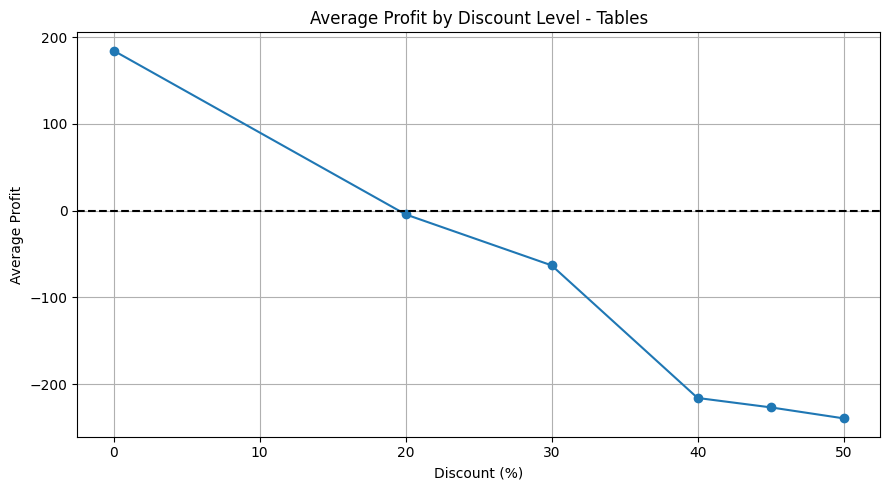

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    tables_analysis.index.to_numpy() * 100,
    tables_analysis["Average_Profit"].to_numpy(),
    marker="o"
)

plt.axhline(y=0, color="black", linestyle="--")
plt.title("Average Profit by Discount Level - Tables")
plt.xlabel("Discount (%)")
plt.ylabel("Average Profit")
plt.grid(True)
plt.tight_layout()
plt.show()

In [59]:
region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Sales"]
) * 100

region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).round(2)

,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
Region,,,,
West,725457.82,108418.45,12266,14.94
East,678781.24,91522.78,10618,13.48
Central,501239.89,39706.36,8780,7.92
South,391721.90,46749.43,6209,11.93


In [60]:
segment_analysis = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
)

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"]
) * 100

segment_analysis.sort_values(
    by="Total_Sales",
    ascending=False
).round(2)

,Total_Sales,Total_Profit,Units_Sold,Profit_Margin
Segment,,,,
Consumer,1161401.34,134119.21,19521,11.55
Corporate,706146.37,91979.13,11608,13.03
Home Office,429653.15,60298.68,6744,14.03


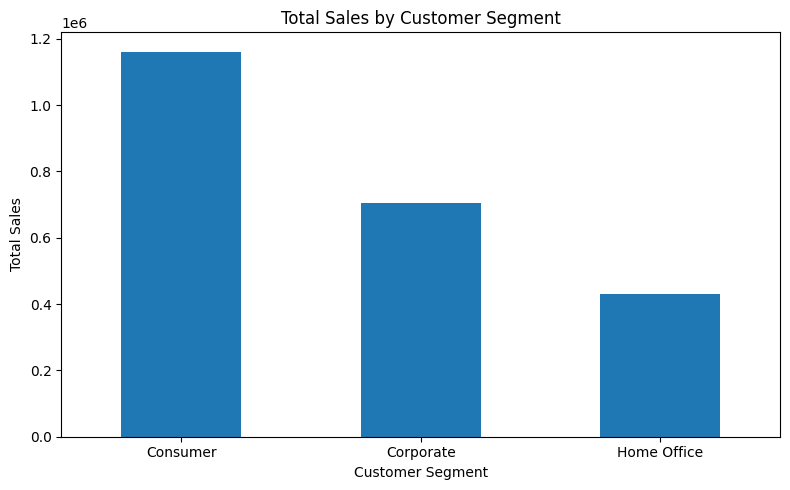

In [61]:
segment_analysis["Total_Sales"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [62]:
region_category = df.pivot_table(
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum"
)

region_category.round(2)

Category,Furniture,Office Supplies,Technology
Region,,,
Central,163797.16,167026.42,170416.31
East,208291.20,205516.06,264973.98
South,117298.68,125651.31,148771.91
West,252612.74,220853.25,251991.83


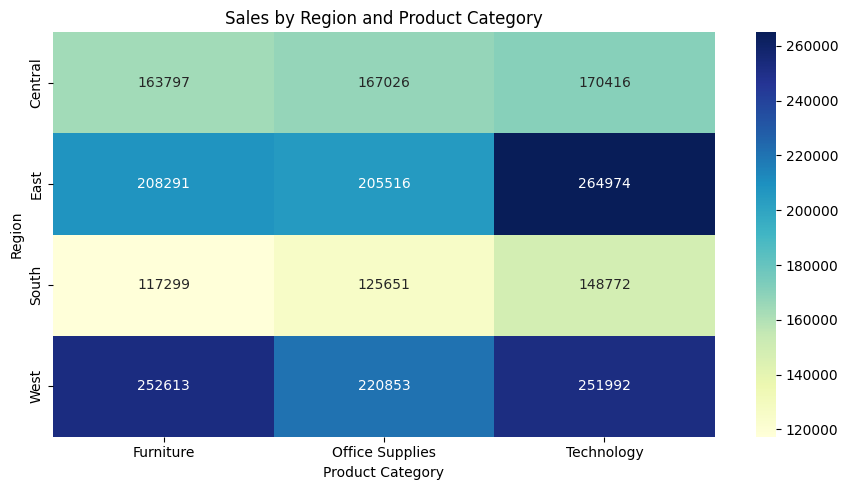

In [63]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    region_category,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Sales by Region and Product Category")
plt.xlabel("Product Category")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

In [64]:
region_category_profit = df.pivot_table(
    index="Region",
    columns="Category",
    values="Profit",
    aggfunc="sum"
)

region_category_profit.round(2)

Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.05,8879.98,33697.43
East,3046.17,41014.58,47462.04
South,6771.21,19986.39,19991.83
West,11504.95,52609.85,44303.65


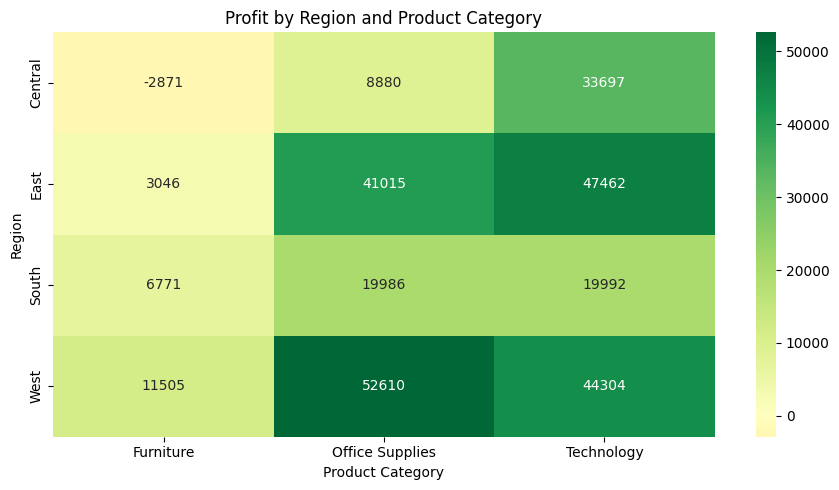

In [65]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    region_category_profit,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    center=0
)

plt.title("Profit by Region and Product Category")
plt.xlabel("Product Category")
plt.ylabel("Region")
plt.tight_layout()
plt.show()